# Auditoria do experimento original

Verificar se o desempenho elevado decorre de vazamento direto, erro de cálculo ou uma simulação fácil. As verificações são evidências limitadas, não uma prova universal de ausência de vazamento. Execute primeiro `python -m ml.robustness.run` para produzir os artefatos desta rodada.

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "ml").is_dir() and (p / "sql").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from ml.data import load_tables
from ml.plotting import configure_style, style_table, save_figure
from ml.config import REPORTS, ARTIFACTS
get_ipython().run_line_magic("matplotlib", "inline")
configure_style()
pd.set_option("display.max_columns", 40)

import json
DESTINATION = ROOT / "ml/reports/robustness/rodada_01"
assert (DESTINATION / "protocolo_registrado.json").exists(), "Execute primeiro python -m ml.robustness.run"


## Testes independentes

1. Recalcular médias e contagens por filtros diretos em 150 transações.
2. Excluir atributos de gabarito, liquidação e snapshots.
3. Multiplicar valores futuros por 20 e adulterar colunas proibidas: atributos passados devem permanecer iguais.
4. Verificar períodos/IDs, cópias exatas, estatísticas do scaler e reprodução das métricas.

Esses testes não avaliam realismo econômico. As mesmas identidades podem aparecer em épocas diferentes; o protocolo original avalia avanço no tempo, não uma população inteiramente nova.

In [2]:
audit = json.loads((DESTINATION / "auditoria.json").read_text(encoding="utf-8"))
table = pd.DataFrame([{"Verificação": row["verificacao"], "Passou": row["aprovado"]} for row in audit["verificacoes"]])
display(style_table(table))


Verificação,Passou
Historicos recalculados de forma independente,True
Whitelist de atributos,True
Mutar futuro e colunas proibidas preserva passado,True
Periodos e identificadores disjuntos,True
Sem copia exata de negocios entre treino e teste,True
Scaler compativel com ajuste apenas no treino,True
Scores e metricas originais reproduzidos,True


## Controle negativo

Embaralhar os rótulos do teste quebra sua associação com os scores congelados. A AP resultante deve se aproximar da prevalência. Este controle não é uma prova causal ou de generalização; nenhum modelo é ajustado às permutações.

ap_observada,ap_permutada_media,ap_permutada_min,ap_permutada_max,prevalencia
0.986400,0.066200,0.061300,0.076600,0.065400


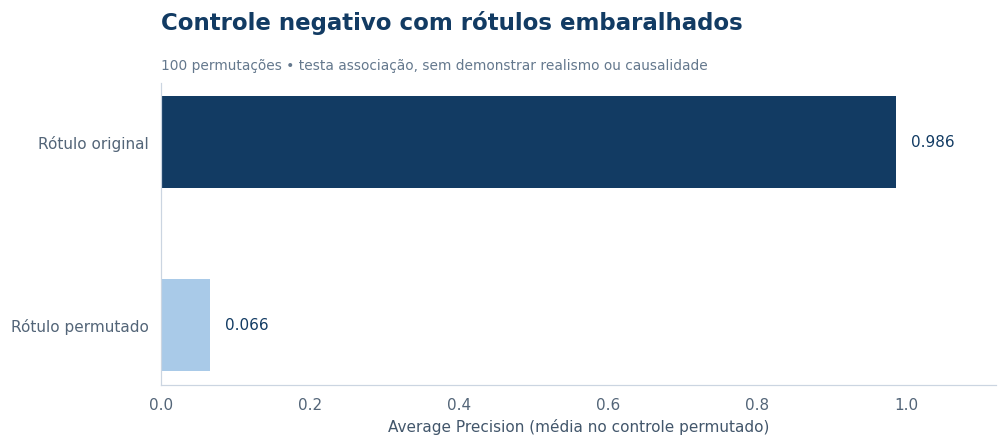

In [3]:
negative = audit["controle_negativo"]
display(style_table(pd.DataFrame([negative]).drop(columns="nota").round(4)))
from ml.robustness.report import make_figures
figures = make_figures(DESTINATION)
display(figures[3])
for figure in figures:
    plt.close(figure)


## Conclusão da auditoria

As verificações registradas não encontraram vazamento direto nem divergência na reprodução dos scores. A queda do controle permutado mostra que os scores estão associados ao rótulo original. Isso deixa aberta a hipótese principal: o gerador cria uma separação especialmente fácil entre valores normais e adulterados.